## Análisis exploratorio de datos (EDA)
Proyecto: clasificación del pago oportuno de créditos

Objetivo: comprender la estructura, calidad, distribución y relaciones de la información antes de entrenar modelos de clasificación.
- Variable objetivo: Pago_atiempo (0 = no pagó a tiempo; 1 = pagó a tiempo).
- Unidad de análisis: registro de crédito.

El EDA describe y documenta los datos. No elimina automáticamente valores extremos ni decide por sí solo qué variables deben usarse en el modelo.
Ejecuta las celdas en orden, desde la primera hasta la última. El notebook busca primero Base_de_datos.csv y, si no está disponible, intenta cargar BD_creditos(3).xlsx o cualquier archivo Excel BD_creditos*.xlsx que esté en la misma carpeta.

# 1. Librerías y carga de datos


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 4)
df = pd.read_csv('../Base_de_datos.csv', encoding='utf-8-sig')
df.head()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,...,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,1852560.0,12,32,Empleado,3500000,1000000,128650,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,916148.0,Creciente,1
1,4,2025-01-09 11:18:48,3181080.0,6,34,Empleado,5000000,2000000,441817,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,4473774.0,Creciente,1
2,9,2024-12-26 18:52:57,670200.0,5,34,Independiente,5000000,2000000,108632,95.227787,...,0.0,274561.0,274561.0,NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,506806.8,2,25,Independiente,3000000,900000,199684,95.227787,...,0.0,27564.0,27564.0,NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,999780.0,10,26,Empleado,2000000,600000,92509,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,61000.0,Creciente,1


In [2]:
df.shape

(10763, 23)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  str    
 2   capital_prestado               10763 non-null  float64
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  str    
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  float64
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null  int64  
 1

## Caracterización de las variables

In [4]:
# Variables categóricas
categoricas = ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos']

# Variable de fecha
fecha = 'fecha_prestamo'

# Variable objetivo
objetivo = 'Pago_atiempo'

# Identificar variables numéricas excluyendo categóricas y variables no utilizadas

variables_excluidas = [
    objetivo,
    "saldo_mora_codeudor"
]

numericas = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in categoricas + variables_excluidas
]

print("Categóricas:", categoricas)
print("Numéricas:", numericas)
print("Variable objetivo:", objetivo)

print("Categóricas:", categoricas)
print("Fecha:", fecha)
print("Numéricas:", numericas)
print("Variable objetivo:", objetivo)

Categóricas: ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos']
Numéricas: ['capital_prestado', 'plazo_meses', 'edad_cliente', 'salario_cliente', 'total_otros_prestamos', 'cuota_pactada', 'puntaje', 'puntaje_datacredito', 'cant_creditosvigentes', 'huella_consulta', 'saldo_mora', 'saldo_total', 'saldo_principal', 'creditos_sectorFinanciero', 'creditos_sectorCooperativo', 'creditos_sectorReal', 'promedio_ingresos_datacredito']
Variable objetivo: Pago_atiempo
Categóricas: ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos']
Fecha: fecha_prestamo
Numéricas: ['capital_prestado', 'plazo_meses', 'edad_cliente', 'salario_cliente', 'total_otros_prestamos', 'cuota_pactada', 'puntaje', 'puntaje_datacredito', 'cant_creditosvigentes', 'huella_consulta', 'saldo_mora', 'saldo_total', 'saldo_principal', 'creditos_sectorFinanciero', 'creditos_sectorCooperativo', 'creditos_sectorReal', 'promedio_ingresos_datacredito']
Variable objetivo: Pago_atiempo


Las variables categóricas pueden ser nominales cuando no tienen un orden, u ordinales cuando sus categorías siguen una secuencia. Las variables dicotómicas tienen dos posibles valores y las politómicas presentan más de dos categorías.

In [5]:
print("Variables nominales:", ["tipo_credito", "tipo_laboral"])
print("Variable ordinal:", "tendencia_ingresos")
print("Variable dicotómica:", "Pago_atiempo")

for columna in categoricas:
    print(f"{columna}: {df[columna].nunique()} categorías")

Variables nominales: ['tipo_credito', 'tipo_laboral']
Variable ordinal: tendencia_ingresos
Variable dicotómica: Pago_atiempo
tipo_credito: 6 categorías
tipo_laboral: 2 categorías
tendencia_ingresos: 46 categorías


tendencia_ingresos tiene un orden natural (Decreciente, Estable y Creciente). tipo_credito y tipo_laboral son categorías sin un orden establecido. Pago_atiempo es dicotómica porque toma los valores 0 y 1.

Revisión de valores nulos

In [6]:
df.isnull().sum().sort_values(ascending=False)

tendencia_ingresos               2932
promedio_ingresos_datacredito    2930
saldo_mora_codeudor               590
saldo_principal                   405
saldo_mora                        156
saldo_total                       156
puntaje_datacredito                 6
salario_cliente                     0
tipo_laboral                        0
edad_cliente                        0
plazo_meses                         0
capital_prestado                    0
fecha_prestamo                      0
tipo_credito                        0
total_otros_prestamos               0
cant_creditosvigentes               0
huella_consulta                     0
cuota_pactada                       0
puntaje                             0
creditos_sectorCooperativo          0
creditos_sectorFinanciero           0
creditos_sectorReal                 0
Pago_atiempo                        0
dtype: int64

In [7]:
(df.isnull().sum() / len(df) * 100).round(2)

tipo_credito                      0.00
fecha_prestamo                    0.00
capital_prestado                  0.00
plazo_meses                       0.00
edad_cliente                      0.00
tipo_laboral                      0.00
salario_cliente                   0.00
total_otros_prestamos             0.00
cuota_pactada                     0.00
puntaje                           0.00
puntaje_datacredito               0.06
cant_creditosvigentes             0.00
huella_consulta                   0.00
saldo_mora                        1.45
saldo_total                       1.45
saldo_principal                   3.76
saldo_mora_codeudor               5.48
creditos_sectorFinanciero         0.00
creditos_sectorCooperativo        0.00
creditos_sectorReal               0.00
promedio_ingresos_datacredito    27.22
tendencia_ingresos               27.24
Pago_atiempo                      0.00
dtype: float64

se identifican valores faltantes principalmente en tendencia_ingresos, promedio_ingresos_datacredito y algunas variables de saldos. Estos valores deben tratarse posteriormente en la preparación de los datos.

Revisar valores repetidos

In [8]:
df.duplicated().sum()

np.int64(0)

Unificar y revisar valores faltantes

In [9]:
df_eda = df.copy()

df_eda.replace(r'^\s*$', np.nan, regex=True, inplace=True)
df_eda.replace(['NA', 'N/A', 'NULL', 'null', 'None'], np.nan, inplace=True)

df_eda.isnull().sum().sort_values(ascending=False).head(10)

tendencia_ingresos               2932
promedio_ingresos_datacredito    2930
saldo_mora_codeudor               590
saldo_principal                   405
saldo_mora                        156
saldo_total                       156
puntaje_datacredito                 6
salario_cliente                     0
tipo_laboral                        0
edad_cliente                        0
dtype: int64

Ajustar tipos de datos

In [10]:
df_eda['fecha_prestamo'] = pd.to_datetime(df_eda['fecha_prestamo'], errors='coerce')
df_eda['tipo_credito'] = df_eda['tipo_credito'].astype('category')
df_eda['tipo_laboral'] = df_eda['tipo_laboral'].astype('category')
df_eda['tendencia_ingresos'] = pd.Categorical(
    df_eda['tendencia_ingresos'],
    categories=['Decreciente', 'Estable', 'Creciente'],
    ordered=True
)

print("Salarios iguales a cero:",
      (df_eda["salario_cliente"] == 0).sum())

print("Puntajes menores o iguales a cero:",
      (df_eda["puntaje_datacredito"] <= 0).sum())

print("Edades menores o iguales a cero:",
      (df_eda["edad_cliente"] <= 0).sum())

print("Capitales negativos:",
      (df_eda["capital_prestado"] < 0).sum())

print("Plazos menores o iguales a cero:",
      (df_eda["plazo_meses"] <= 0).sum())

df_eda.dtypes

Salarios iguales a cero: 24
Puntajes menores o iguales a cero: 146
Edades menores o iguales a cero: 0
Capitales negativos: 0
Plazos menores o iguales a cero: 0


C:\Users\Elena\AppData\Local\Temp\ipykernel_20272\698160932.py:4: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  df_eda['tendencia_ingresos'] = pd.Categorical(


tipo_credito                           category
fecha_prestamo                   datetime64[us]
capital_prestado                        float64
plazo_meses                               int64
edad_cliente                              int64
tipo_laboral                           category
salario_cliente                           int64
total_otros_prestamos                     int64
cuota_pactada                             int64
puntaje                                 float64
puntaje_datacredito                     float64
cant_creditosvigentes                     int64
huella_consulta                           int64
saldo_mora                              float64
saldo_total                             float64
saldo_principal                         float64
saldo_mora_codeudor                     float64
creditos_sectorFinanciero                 int64
creditos_sectorCooperativo                int64
creditos_sectorReal                       int64
promedio_ingresos_datacredito           

In [11]:
# Corrección de inconsistencias identificadas

# Los salarios iguales a cero se consideran valores faltantes
df_eda.loc[df_eda["salario_cliente"] == 0, "salario_cliente"] = np.nan

# Los puntajes menores o iguales a cero se consideran valores faltantes
df_eda.loc[df_eda["puntaje_datacredito"] <= 0, "puntaje_datacredito"] = np.nan

# Conservar únicamente las categorías válidas de tendencia de ingresos
categorias_validas = ["Decreciente", "Estable", "Creciente"]

df_eda["tendencia_ingresos"] = df_eda["tendencia_ingresos"].where(
    df_eda["tendencia_ingresos"].isin(categorias_validas),
    np.nan
)

print("Inconsistencias tratadas:")
print("Salarios iguales a cero:", (df_eda["salario_cliente"] == 0).sum())
print("Puntajes menores o iguales a cero:",
      (df_eda["puntaje_datacredito"] <= 0).sum())
print("Valores no válidos en tendencia_ingresos:",
      (~df_eda["tendencia_ingresos"].isin(categorias_validas) &
       df_eda["tendencia_ingresos"].notna()).sum())

Inconsistencias tratadas:
Salarios iguales a cero: 0
Puntajes menores o iguales a cero: 0
Valores no válidos en tendencia_ingresos: 0


In [12]:
# Tratar edades superiores a 100 años como valores faltantes

df_eda.loc[df_eda["edad_cliente"] > 100, "edad_cliente"] = np.nan

print("Edades superiores a 100:",
      (df_eda["edad_cliente"] > 100).sum())

print("Valores faltantes en edad_cliente:",
      df_eda["edad_cliente"].isna().sum())

Edades superiores a 100: 0
Valores faltantes en edad_cliente: 150


### Tratamiento de inconsistencias

Durante la revisión de los datos se identificaron valores que requerían tratamiento:

- Los salarios iguales a cero se convirtieron en valores nulos, debido a que no representan un salario válido para el análisis.
- Los puntajes de Datacrédito menores o iguales a cero se convirtieron en valores nulos.
- En `tendencia_ingresos` se conservaron únicamente las categorías Decreciente, Estable y Creciente. Los valores diferentes se trataron como faltantes.

Estas correcciones permiten mantener una representación uniforme de los datos. Los valores faltantes resultantes serán tratados posteriormente durante la ingeniería de características.

Revisar variables que podrían no aportar información

In [13]:
df_eda.nunique(dropna=False).sort_values()

tipo_laboral                         2
Pago_atiempo                         2
tendencia_ingresos                   4
saldo_mora_codeudor                  5
tipo_credito                         6
creditos_sectorCooperativo          11
plazo_meses                         18
creditos_sectorReal                 24
huella_consulta                     28
creditos_sectorFinanciero           33
cant_creditosvigentes               39
edad_cliente                        52
saldo_mora                          56
puntaje                            248
puntaje_datacredito                314
salario_cliente                   1385
total_otros_prestamos             1538
promedio_ingresos_datacredito     5310
capital_prestado                  7306
saldo_principal                   8648
saldo_total                       8859
cuota_pactada                     9836
fecha_prestamo                   10758
dtype: int64

In [14]:
df_eda["saldo_mora_codeudor"].value_counts(dropna=False)

saldo_mora_codeudor
0.0       10170
NaN         590
30.0          1
470.0         1
2145.0        1
Name: count, dtype: int64

### Decisión sobre la variable `saldo_mora_codeudor`

Se identificó que esta variable presenta 10.170 registros con valor cero, 590 valores nulos y solamente 3 registros con valores diferentes de cero. Esto indica que la variable tiene una variabilidad muy baja y que la información disponible es insuficiente para representar un patrón consistente en los datos.

Por esta razón, se considera una variable de baja relevancia para el proceso de modelado y se decide excluirla de las variables utilizadas para entrenar los modelos predictivos.

Estadísticas descriptivas

In [15]:
display(df_eda.describe(include='all').T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
tipo_credito,10763.0,6.0,4.0,7747.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_prestamo,10763,NaN,NaN,NaN,2025-04-16 23:06:02.111121,2024-11-26 09:17:04,2025-01-20 17:33:07.500000,2025-03-27 16:23:12,2025-06-16 13:27:58,2026-04-26 18:43:52,NaN
capital_prestado,10763.0,NaN,NaN,NaN,2434315.001319,360000.0,1224831.0,1921920.0,3084840.0,41444152.8,1909642.758997
plazo_meses,10763.0,NaN,NaN,NaN,10.575583,2.0,6.0,10.0,12.0,90.0,6.632082
edad_cliente,10613.0,NaN,NaN,NaN,42.845661,19.0,33.0,42.0,52.0,69.0,11.947307
tipo_laboral,10763,2,Empleado,6754,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salario_cliente,10739.0,NaN,NaN,NaN,17254907.514946,1000.0,2000000.0,3000000.0,4900000.0,22000000000.0,355872817.682813
total_otros_prestamos,10763.0,NaN,NaN,NaN,6238869.648518,0.0,500000.0,1000000.0,2000000.0,6787675263.0,118418316.941069
cuota_pactada,10763.0,NaN,NaN,NaN,243617.406671,23944.0,121041.5,182863.0,287833.5,3816752.0,210493.694608
puntaje,10763.0,NaN,NaN,NaN,91.170036,-38.00999,95.227787,95.227787,95.227787,95.227787,16.465441


In [16]:
df_eda[numericas].agg(['mean', 'median', 'min', 'max', 'std']).T

,mean,median,min,max,std
capital_prestado,2.434315e+06,1.921920e+06,360000.00000,4.144415e+07,1.909643e+06
plazo_meses,1.057558e+01,1.000000e+01,2.00000,9.000000e+01,6.632082e+00
edad_cliente,4.284566e+01,4.200000e+01,19.00000,6.900000e+01,1.194731e+01
salario_cliente,1.725491e+07,3.000000e+06,1000.00000,2.200000e+10,3.558728e+08
total_otros_prestamos,6.238870e+06,1.000000e+06,0.00000,6.787675e+09,1.184183e+08
cuota_pactada,2.436174e+05,1.828630e+05,23944.00000,3.816752e+06,2.104937e+05
puntaje,9.117004e+01,9.522779e+01,-38.00999,9.522779e+01,1.646544e+01
puntaje_datacredito,7.915346e+02,7.920000e+02,7.00000,9.990000e+02,5.143295e+01
cant_creditosvigentes,5.726749e+00,5.000000e+00,0.00000,6.200000e+01,3.977162e+00
huella_consulta,4.228561e+00,4.000000e+00,0.00000,2.900000e+01,3.064683e+00


In [17]:
estadisticas = pd.DataFrame(index=numericas)

estadisticas["Media"] = df_eda[numericas].mean()
estadisticas["Mediana"] = df_eda[numericas].median()
estadisticas["Moda"] = df_eda[numericas].mode().iloc[0]
estadisticas["Mínimo"] = df_eda[numericas].min()
estadisticas["Máximo"] = df_eda[numericas].max()
estadisticas["Rango"] = estadisticas["Máximo"] - estadisticas["Mínimo"]
estadisticas["Q1"] = df_eda[numericas].quantile(0.25)
estadisticas["Q3"] = df_eda[numericas].quantile(0.75)
estadisticas["IQR"] = estadisticas["Q3"] - estadisticas["Q1"]
estadisticas["Varianza"] = df_eda[numericas].var()
estadisticas["Desviación estándar"] = df_eda[numericas].std()
estadisticas["Skewness"] = df_eda[numericas].skew()
estadisticas["Kurtosis"] = df_eda[numericas].kurtosis()

display(estadisticas.round(2))

,Media,Mediana,Moda,Mínimo,Máximo,Rango,Q1,Q3,IQR,Varianza,Desviación estándar,Skewness,Kurtosis
capital_prestado,2434315.00,1921920.00,1200000.00,360000.00,4.144415e+07,4.108415e+07,1224831.00,3084840.00,1860009.00,3.646735e+12,1.909643e+06,3.72,35.32
plazo_meses,10.58,10.00,6.00,2.00,9.000000e+01,8.800000e+01,6.00,12.00,6.00,4.398000e+01,6.630000e+00,2.46,7.78
edad_cliente,42.85,42.00,40.00,19.00,6.900000e+01,5.000000e+01,33.00,52.00,19.00,1.427400e+02,1.195000e+01,0.27,-0.86
salario_cliente,17254907.51,3000000.00,3000000.00,1000.00,2.200000e+10,2.200000e+10,2000000.00,4900000.00,2900000.00,1.266455e+17,3.558728e+08,43.73,2206.30
total_otros_prestamos,6238869.65,1000000.00,2000000.00,0.00,6.787675e+09,6.787675e+09,500000.00,2000000.00,1500000.00,1.402290e+16,1.184183e+08,38.46,1719.28
cuota_pactada,243617.41,182863.00,205990.00,23944.00,3.816752e+06,3.792808e+06,121041.50,287833.50,166792.00,4.430760e+10,2.104937e+05,3.79,26.65
puntaje,91.17,95.23,95.23,-38.01,9.523000e+01,1.332400e+02,95.23,95.23,0.00,2.711100e+02,1.647000e+01,-4.87,24.08
puntaje_datacredito,791.53,792.00,783.00,7.00,9.990000e+02,9.920000e+02,758.00,826.00,68.00,2.645350e+03,5.143000e+01,-0.99,9.98
cant_creditosvigentes,5.73,5.00,4.00,0.00,6.200000e+01,6.200000e+01,3.00,8.00,5.00,1.582000e+01,3.980000e+00,1.80,8.62
huella_consulta,4.23,4.00,2.00,0.00,2.900000e+01,2.900000e+01,2.00,6.00,4.00,9.390000e+00,3.060000e+00,1.49,4.00


## Análisis de variables numéricas

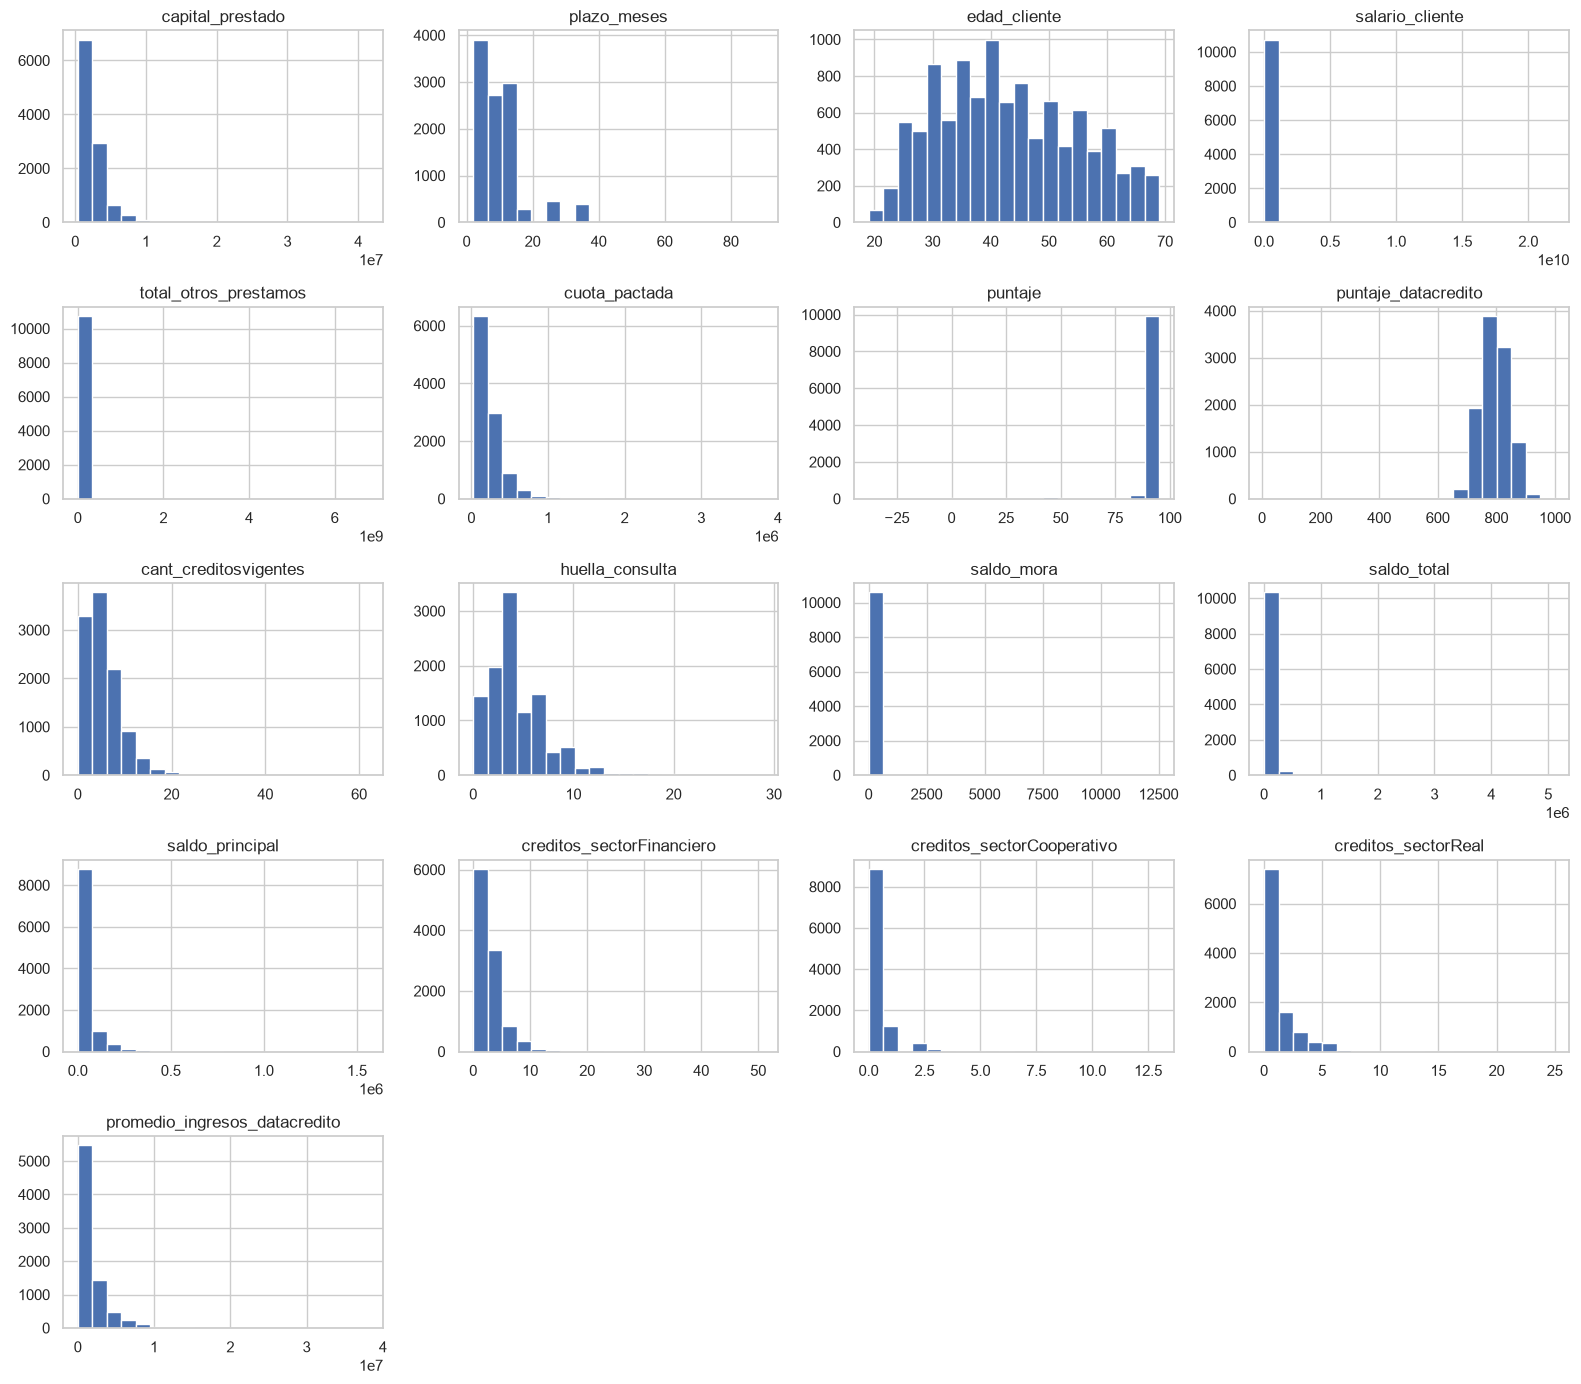

In [18]:
df_eda[numericas].hist(figsize=(16, 14), bins=20)
plt.tight_layout()
plt.show()

In [19]:
for columna in numericas:
    asimetria = df_eda[columna].skew()

    if asimetria > 0.5:
        distribucion = "Asimetría positiva"
    elif asimetria < -0.5:
        distribucion = "Asimetría negativa"
    else:
        distribucion = "Aproximadamente simétrica"

    print(columna, ":", distribucion)

capital_prestado : Asimetría positiva
plazo_meses : Asimetría positiva
edad_cliente : Aproximadamente simétrica
salario_cliente : Asimetría positiva
total_otros_prestamos : Asimetría positiva
cuota_pactada : Asimetría positiva
puntaje : Asimetría negativa
puntaje_datacredito : Asimetría negativa
cant_creditosvigentes : Asimetría positiva
huella_consulta : Asimetría positiva
saldo_mora : Asimetría positiva
saldo_total : Asimetría positiva
saldo_principal : Asimetría positiva
creditos_sectorFinanciero : Asimetría positiva
creditos_sectorCooperativo : Asimetría positiva
creditos_sectorReal : Asimetría positiva
promedio_ingresos_datacredito : Asimetría positiva


### Interpretación de las distribuciones numéricas

A partir del análisis de asimetría se observa que la mayoría de las variables numéricas presentan distribuciones con asimetría positiva. Esto significa que sus valores se concentran principalmente en niveles bajos o intermedios, mientras que existen algunos registros con valores considerablemente altos que generan una cola hacia la derecha.

Este comportamiento se evidencia especialmente en variables relacionadas con ingresos, capital prestado, otros préstamos y saldos financieros. Por lo tanto, sus medias pueden verse afectadas por los valores extremos y es importante complementarlas con la mediana y los diagramas de caja.

Por otra parte, variables como `puntaje` y `puntaje_datacredito` presentan asimetría negativa, lo que indica una mayor concentración de observaciones hacia los valores altos y una cola hacia los valores inferiores.

En general, las distribuciones no son completamente simétricas, por lo que esta característica debe tenerse en cuenta durante la preparación de los datos y la selección de los modelos.

Diagramas de caja (boxplots)

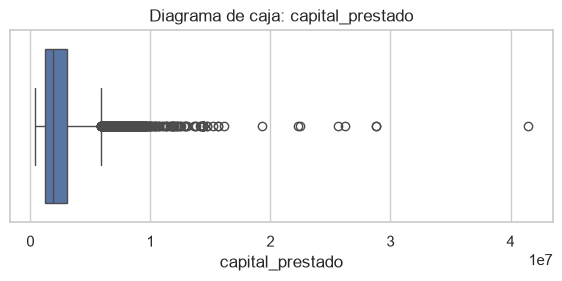

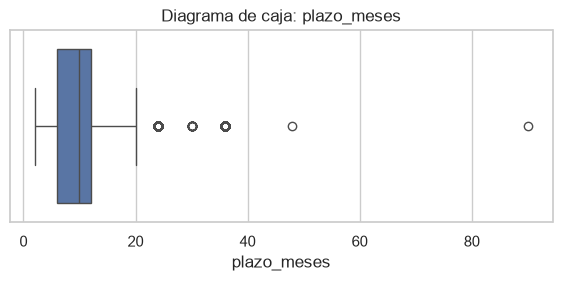

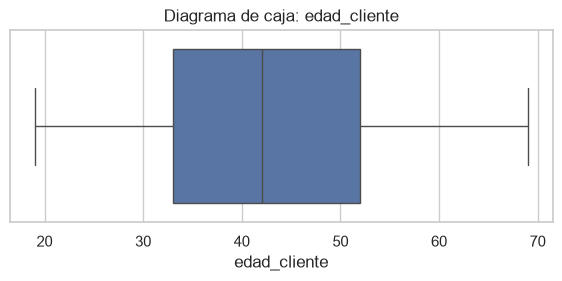

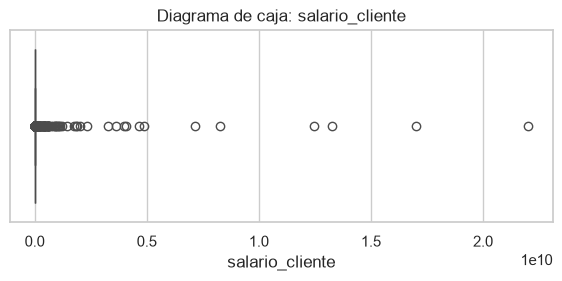

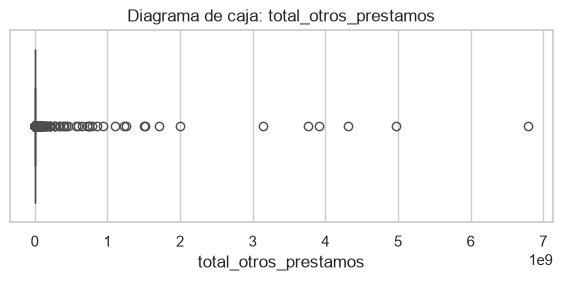

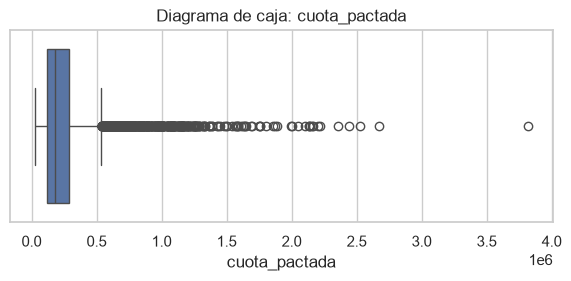

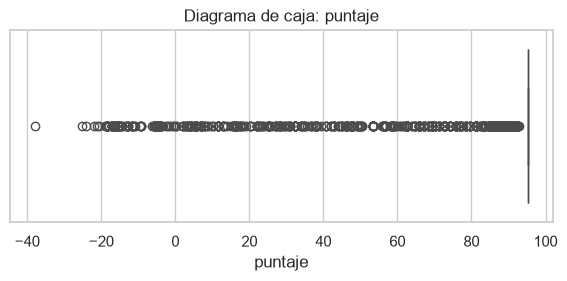

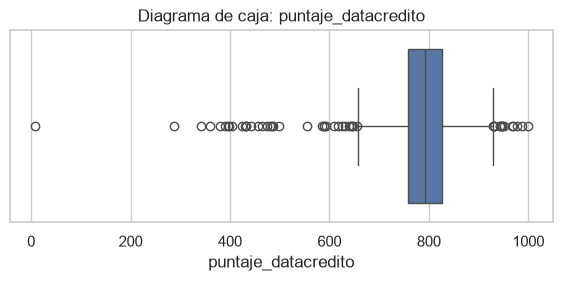

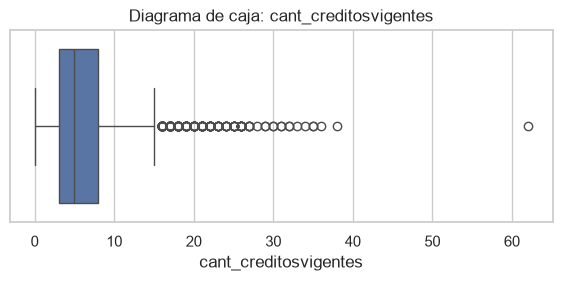

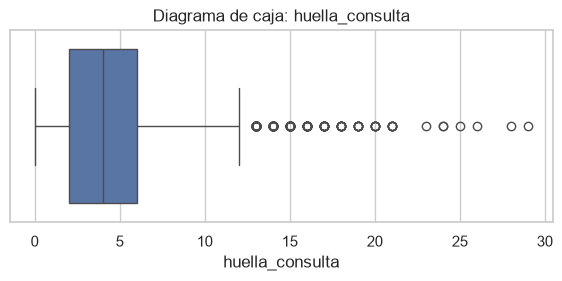

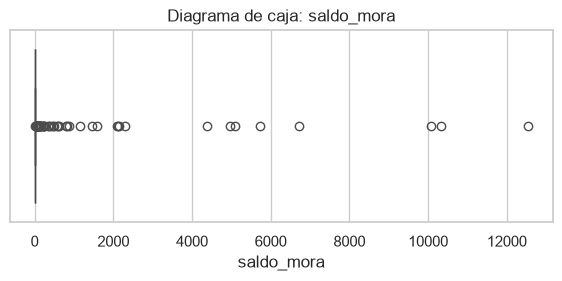

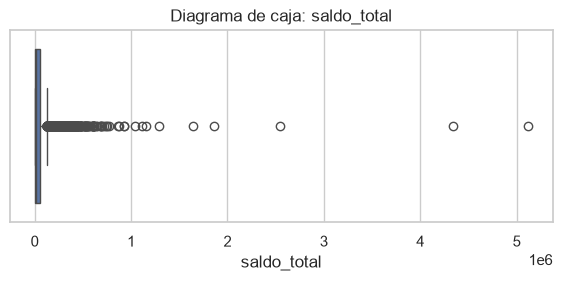

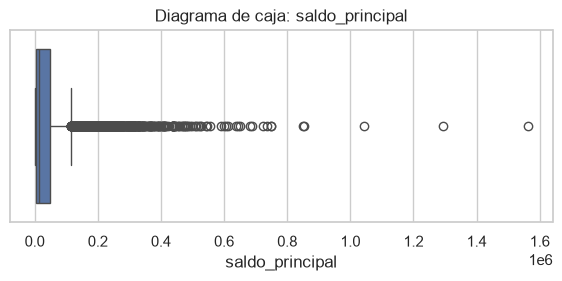

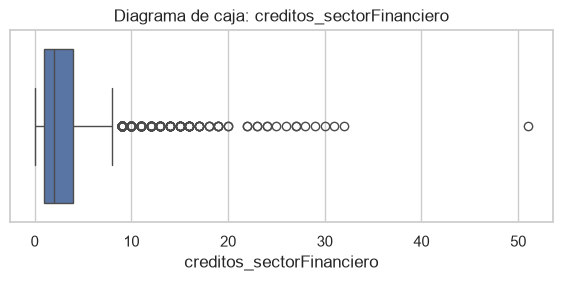

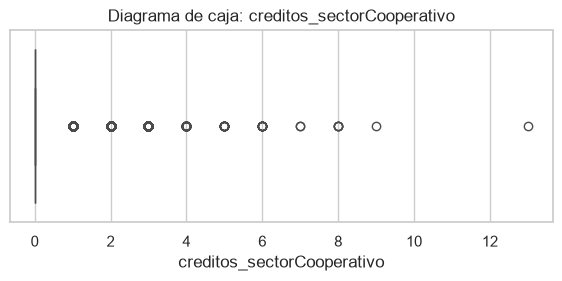

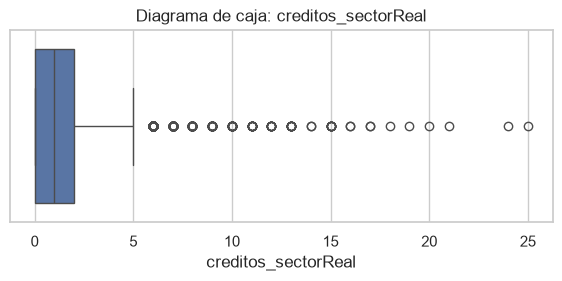

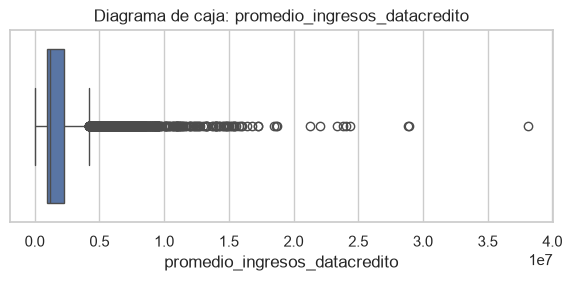

In [20]:
for columna in numericas:
    plt.figure(figsize=(7, 2.5))
    sns.boxplot(x=df_eda[columna])
    plt.title(f'Diagrama de caja: {columna}')
    plt.show()

In [21]:
for columna in numericas:
    asimetria = df_eda[columna].skew()

    if asimetria > 0.5:
        distribucion = "Asimetría positiva"
    elif asimetria < -0.5:
        distribucion = "Asimetría negativa"
    else:
        distribucion = "Aproximadamente simétrica"

    print(columna, ":", distribucion)

capital_prestado : Asimetría positiva
plazo_meses : Asimetría positiva
edad_cliente : Aproximadamente simétrica
salario_cliente : Asimetría positiva
total_otros_prestamos : Asimetría positiva
cuota_pactada : Asimetría positiva
puntaje : Asimetría negativa
puntaje_datacredito : Asimetría negativa
cant_creditosvigentes : Asimetría positiva
huella_consulta : Asimetría positiva
saldo_mora : Asimetría positiva
saldo_total : Asimetría positiva
saldo_principal : Asimetría positiva
creditos_sectorFinanciero : Asimetría positiva
creditos_sectorCooperativo : Asimetría positiva
creditos_sectorReal : Asimetría positiva
promedio_ingresos_datacredito : Asimetría positiva


Análisis de variables categóricas

In [22]:
for columna in categoricas:
    print('\nFrecuencia de', columna)
    display(df_eda[columna].value_counts(dropna=False).to_frame('Cantidad'))


Frecuencia de tipo_credito


,Cantidad
tipo_credito,
4,7747
9,2876
10,116
6,21
7,2
68,1



Frecuencia de tipo_laboral


,Cantidad
tipo_laboral,
Empleado,6754
Independiente,4009



Frecuencia de tendencia_ingresos


,Cantidad
tendencia_ingresos,
Creciente,5294
NaN,2990
Decreciente,1291
Estable,1188


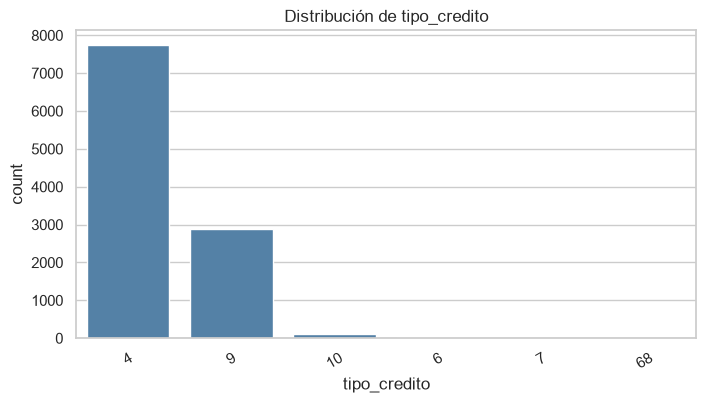

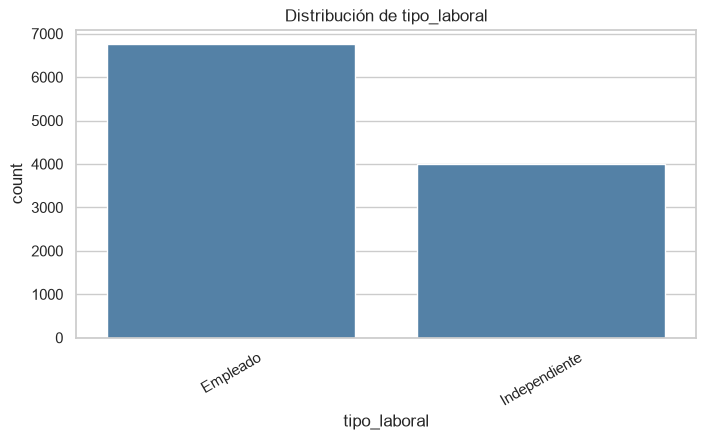

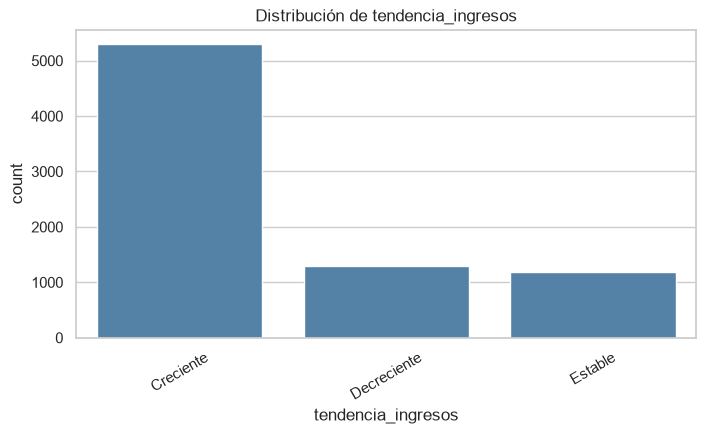

In [23]:
for columna in categoricas:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df_eda, x=columna, order=df_eda[columna].value_counts().index, color='steelblue')
    plt.title(f'Distribución de {columna}')
    plt.xticks(rotation=30)
    plt.show()

## Análisis de la variable objetivo
La variable Pago_atiempo indica si el crédito fue pagado a tiempo: 1 representa pago a tiempo y 0 representa que no se pagó a tiempo.

In [24]:
print(df_eda[objetivo].value_counts())
print('\nPorcentaje:')
display((df_eda[objetivo].value_counts(normalize=True) * 100).round(2))

Pago_atiempo
1    10252
0      511
Name: count, dtype: int64

Porcentaje:


Pago_atiempo
1    95.25
0     4.75
Name: proportion, dtype: float64

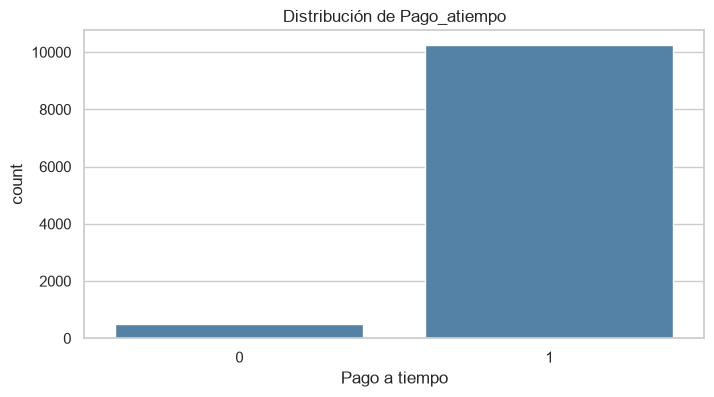

In [25]:
sns.countplot(data=df_eda, x=objetivo, color='steelblue')
plt.title('Distribución de Pago_atiempo')
plt.xlabel('Pago a tiempo')
plt.show()

la distribución de la variable objetivo permite identificar si las clases están equilibradas. Este resultado debe tenerse en cuenta al entrenar y evaluar los modelos.

Análisis de variables categóricas frente al objetivo

In [26]:
for columna in categoricas:
    print('\n', columna, 'frente a', objetivo)
    tabla = pd.crosstab(df_eda[columna], df_eda[objetivo], normalize='index') * 100
    display(tabla.round(2))


 tipo_credito frente a Pago_atiempo


Pago_atiempo,0,1
tipo_credito,,
4,4.69,95.31
6,42.86,57.14
7,0.00,100.00
9,4.73,95.27
10,2.59,97.41
68,0.00,100.00



 tipo_laboral frente a Pago_atiempo


Pago_atiempo,0,1
tipo_laboral,,
Empleado,4.29,95.71
Independiente,5.51,94.49



 tendencia_ingresos frente a Pago_atiempo


Pago_atiempo,0,1
tendencia_ingresos,,
Decreciente,6.27,93.73
Estable,4.63,95.37
Creciente,3.91,96.09


C:\Users\Elena\AppData\Local\Temp\ipykernel_20272\997598290.py:3: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:steelblue'` for the same effect.

  sns.countplot(data=df_eda, x=columna, hue=objetivo, color='steelblue')


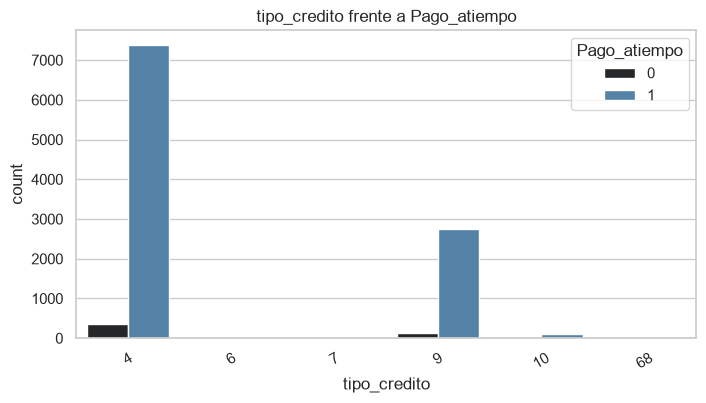

C:\Users\Elena\AppData\Local\Temp\ipykernel_20272\997598290.py:3: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:steelblue'` for the same effect.

  sns.countplot(data=df_eda, x=columna, hue=objetivo, color='steelblue')


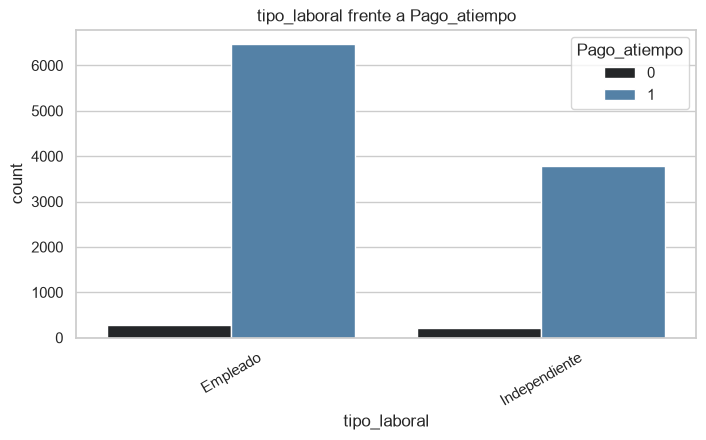

C:\Users\Elena\AppData\Local\Temp\ipykernel_20272\997598290.py:3: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:steelblue'` for the same effect.

  sns.countplot(data=df_eda, x=columna, hue=objetivo, color='steelblue')


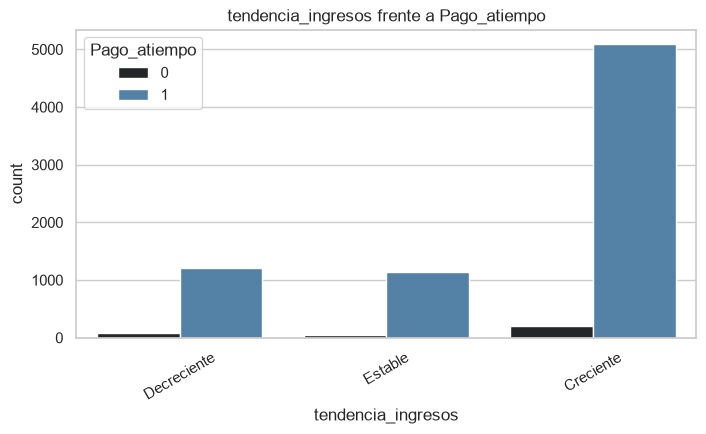

In [27]:
for columna in categoricas:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df_eda, x=columna, hue=objetivo, color='steelblue')
    plt.title(f'{columna} frente a {objetivo}')
    plt.xticks(rotation=30)
    plt.show()

### Interpretación del análisis bivariado categórico

Al comparar las variables categóricas con `Pago_atiempo`, se observa que la mayoría de los registros corresponden a clientes que pagaron a tiempo.

En `tipo_laboral`, los empleados presentan un porcentaje de pago oportuno del 95,71 %, mientras que para los trabajadores independientes es del 94,49 %.

En `tendencia_ingresos`, los clientes con tendencia creciente presentan un porcentaje de pago oportuno del 96,09 %, seguidos por quienes tienen ingresos estables (95,37 %) y decrecientes (93,73 %).

En `tipo_credito` se observan diferencias entre categorías, aunque algunas tienen pocos registros, por lo que sus porcentajes deben interpretarse con precaución.

Estos resultados permiten identificar posibles asociaciones entre las características de los clientes y el pago oportuno, pero no demuestran por sí solos una relación causal.

In [28]:
tabla_pivote = pd.pivot_table(
    df_eda,
    index="tipo_laboral",
    columns="tendencia_ingresos",
    values=objetivo,
    aggfunc="mean"
)

display((tabla_pivote * 100).round(2))

tendencia_ingresos,Decreciente,Estable,Creciente
tipo_laboral,,,
Empleado,94.13,95.51,96.44
Independiente,92.66,95.20,95.18


Análisis de variables numéricas frente al objetivo

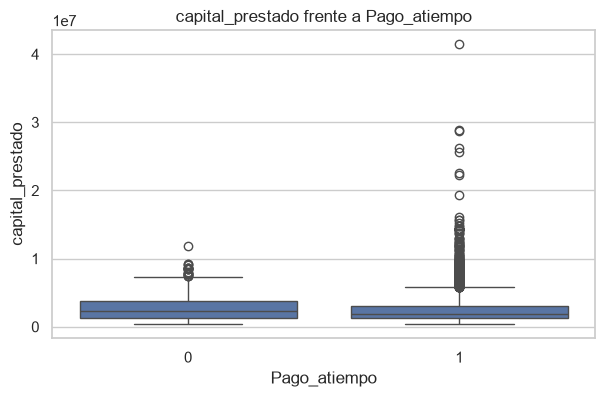

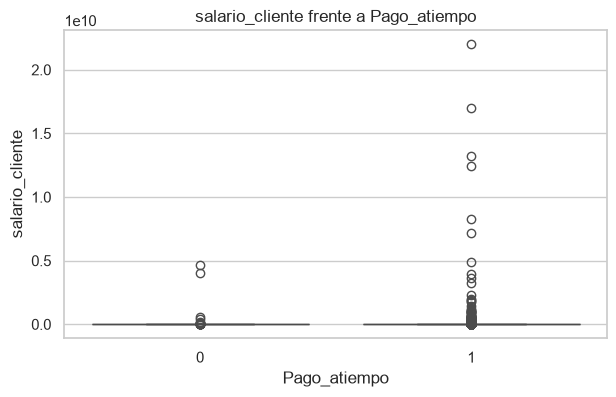

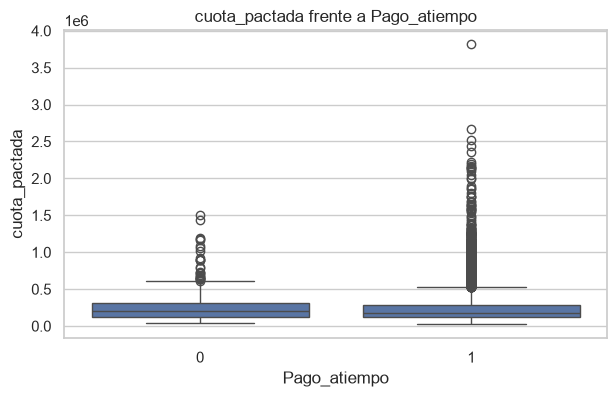

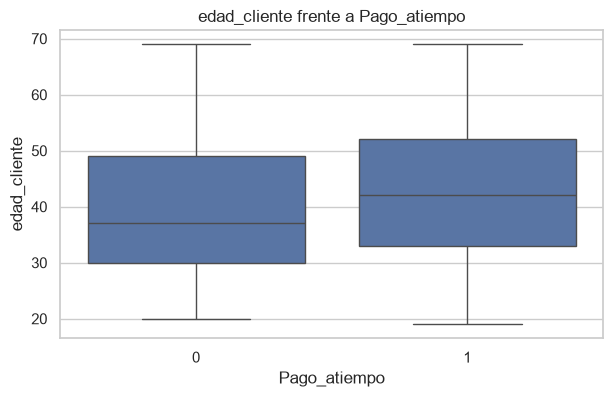

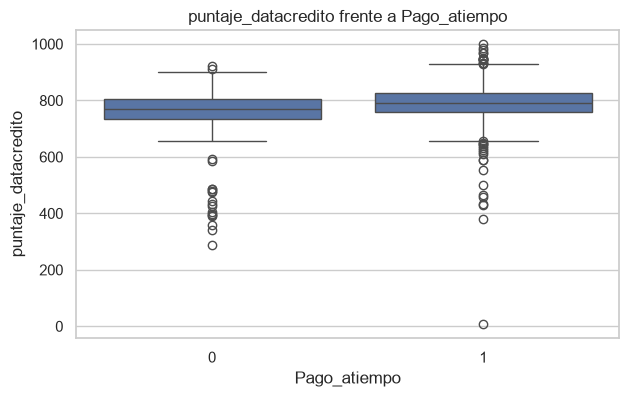

In [29]:
variables_revision = ['capital_prestado', 'salario_cliente', 'cuota_pactada',
                       'edad_cliente', 'puntaje_datacredito']

for columna in variables_revision:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df_eda, x=objetivo, y=columna)
    plt.title(f'{columna} frente a {objetivo}')
    plt.show()

Relación entre variables numéricas

La matriz de correlación permite observar si algunas variables numéricas presentan relaciones entre sí.

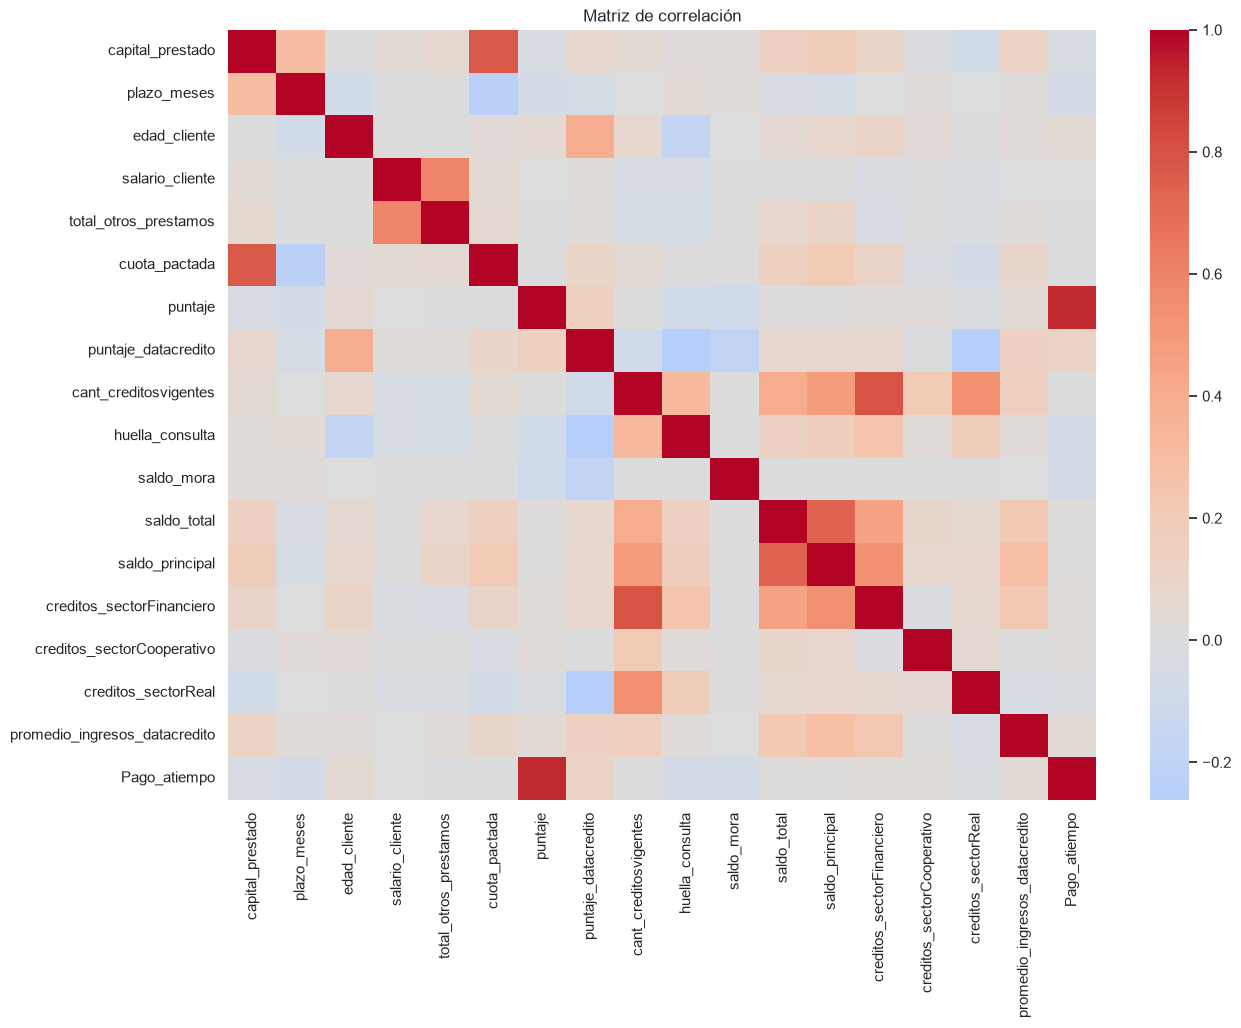

In [30]:
correlacion = df_eda[numericas + [objetivo]].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(correlacion, cmap='coolwarm', center=0)
plt.title('Matriz de correlación')
plt.show()

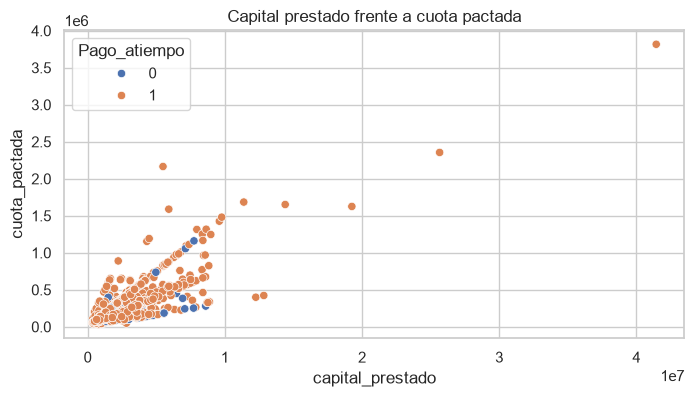

In [31]:
sns.scatterplot(data=df_eda.sample(min(1500, len(df_eda)), random_state=42),
                x='capital_prestado', y='cuota_pactada', hue=objetivo)
plt.title('Capital prestado frente a cuota pactada')
plt.show()

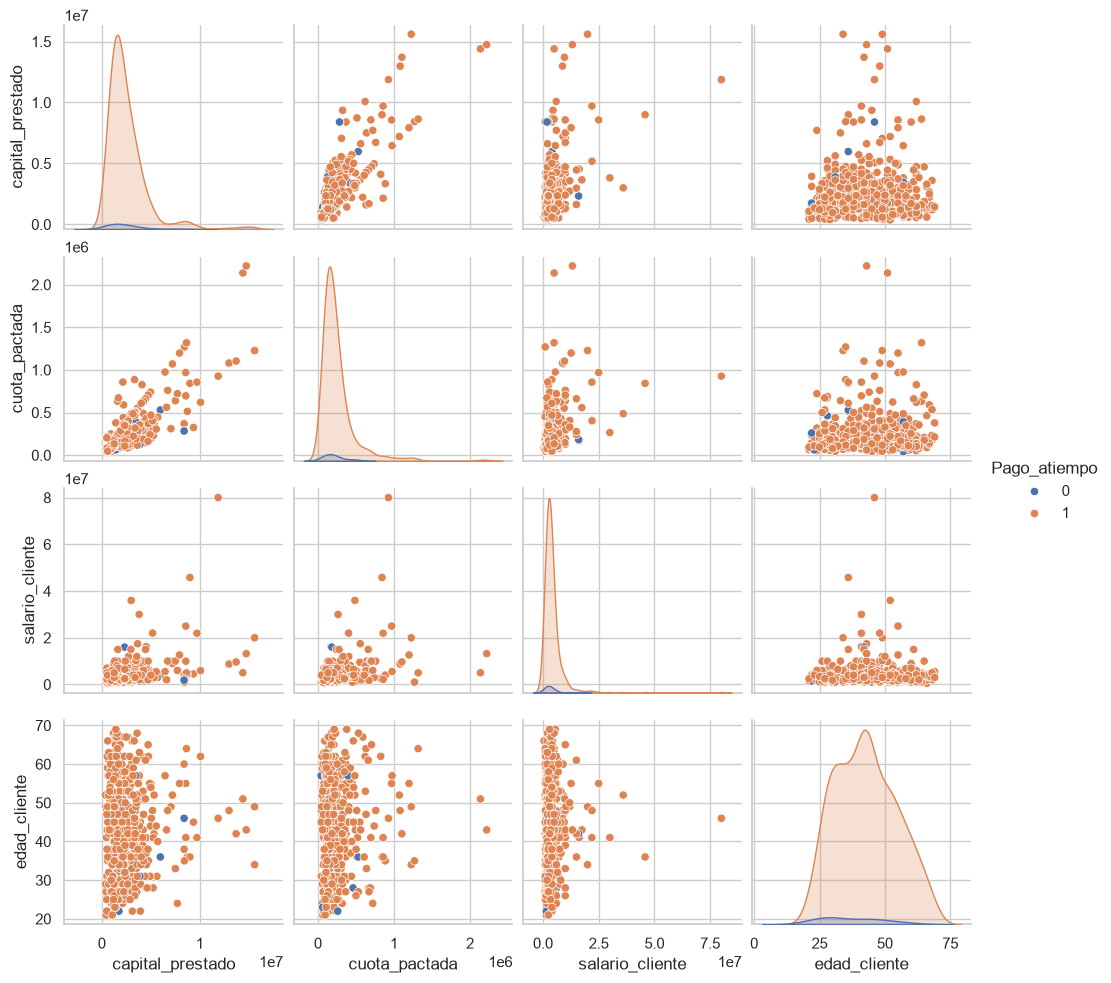

In [32]:
datos_pairplot = df_eda[
    ["capital_prestado", "cuota_pactada",
     "salario_cliente", "edad_cliente", objetivo]
].dropna()

datos_pairplot = datos_pairplot.sample(
    min(500, len(datos_pairplot)),
    random_state=42
)

sns.pairplot(datos_pairplot, hue=objetivo)
plt.show()

### Interpretación del análisis multivariado

La matriz de correlación y los gráficos de dispersión permiten explorar las relaciones entre las variables numéricas.

Se analiza especialmente la relación entre el capital prestado y la cuota pactada, debido a que ambas variables están relacionadas con las condiciones financieras del crédito. También se incluyen el salario y la edad para observar cómo se distribuyen estas características entre los registros de pago oportuno y no oportuno.

El análisis multivariado permite identificar posibles relaciones y patrones entre varias características. Sin embargo, estas asociaciones deben complementarse con la evaluación de los modelos predictivos para determinar su utilidad en la clasificación del pago oportuno.

Reglas de validación identificadas
A partir de la revisión de los datos, se proponen las siguientes reglas para una etapa posterior de preparación

In [33]:
# Comprobación de reglas de validación

print("1. Edades menores o iguales a cero:",
      (df_eda["edad_cliente"] <= 0).sum())

print("   Edades mayores a 100:",
      (df_eda["edad_cliente"] > 100).sum())

print("2. Capital prestado negativo:",
      (df_eda["capital_prestado"] < 0).sum())

print("   Salarios negativos:",
      (df_eda["salario_cliente"] < 0).sum())

print("   Cuotas negativas:",
      (df_eda["cuota_pactada"] < 0).sum())

print("3. Plazos menores o iguales a cero:",
      (df_eda["plazo_meses"] <= 0).sum())

print("4. Valores inválidos en la variable objetivo:",
      (~df_eda["Pago_atiempo"].isin([0, 1])).sum())

print("5. Fechas inválidas o faltantes:",
      df_eda["fecha_prestamo"].isna().sum())

print("6. Categorías inválidas en tendencia_ingresos:",
      (~df_eda["tendencia_ingresos"].isin(
          ["Decreciente", "Estable", "Creciente"]
      ) & df_eda["tendencia_ingresos"].notna()).sum())

1. Edades menores o iguales a cero: 0
   Edades mayores a 100: 0
2. Capital prestado negativo: 0
   Salarios negativos: 0
   Cuotas negativas: 0
3. Plazos menores o iguales a cero: 0
4. Valores inválidos en la variable objetivo: 0
5. Fechas inválidas o faltantes: 0
6. Categorías inválidas en tendencia_ingresos: 0


In [34]:
# Revisar edades superiores a 100 años

df_eda.loc[
    df_eda["edad_cliente"] > 100,
    "edad_cliente"
].value_counts().sort_index()

Series([], Name: count, dtype: int64)

In [35]:
reglas = [
    'La edad del cliente debe ser un valor positivo y razonable.',
    'El capital prestado, el salario y la cuota no deberían ser negativos.',
    'El plazo del crédito debe ser mayor que cero.',
    'Pago_atiempo solo debe contener los valores 0 y 1.',
    'La fecha del préstamo debe tener un formato de fecha válido.',
    'Las categorías de tendencia_ingresos deben ser Decreciente, Estable o Creciente.'
]

for regla in reglas:
    print('-', regla)

- La edad del cliente debe ser un valor positivo y razonable.
- El capital prestado, el salario y la cuota no deberían ser negativos.
- El plazo del crédito debe ser mayor que cero.
- Pago_atiempo solo debe contener los valores 0 y 1.
- La fecha del préstamo debe tener un formato de fecha válido.
- Las categorías de tendencia_ingresos deben ser Decreciente, Estable o Creciente.


In [ ]:
df_eda["cuota_sobre_salario"] = (
    df_eda["cuota_pactada"] /
    df_eda["salario_cliente"].replace(0, np.nan)
)

df_eda["mes_prestamo"] = df_eda["fecha_prestamo"].dt.month

df_eda[["cuota_sobre_salario", "mes_prestamo"]].head()

,cuota_sobre_salario,mes_prestamo
0,0.036757,1
1,0.088363,1
2,0.021726,12
3,0.066561,12
4,0.046254,4


: 